# Gaussian beam decomposition through a lens system: a spatial filter

A laser beam that has passed a few dusty or scratched optics, or picked up a
ghost reflection, is no longer a clean Gaussian. The standard cure is a
**spatial filter**: a lens focuses the beam onto a pinhole, a second lens
collimates what passes. The pinhole sits in the back focal plane of the
first lens, where every *direction* of the input beam has its own *place*:
the clean beam is the bright spot on the axis, the ripple and the ghost are
light that travels in other directions and lands beside it. The pinhole is a
low-pass filter on the angular spectrum, the experiment that Abbe and Porter
used to explain image formation in the microscope (notebook
[52](52_abbe_image_formation.ipynb), Abbe/Porter filtering).

The spatial filter is a system where diffraction *inside* the optics
matters. The focus is a waist, and geometrical optics cannot pass a
waist. The pinhole cuts the field where it is a few micrometres wide, and
behind it the light spreads by diffraction alone. This notebook carries the
field through the lenses with **Gaussian beam decomposition (GBD)**: the
field is written as a sum of narrow Gaussian beamlets, each beamlet follows
its own ray through the real lens surfaces, and the beamlets are summed
coherently wherever the field is needed.

Notebook [47](47_rays_and_waves.ipynb) (section 5) launched beamlets
*behind* a lens from a traced ray grid and propagated them through free
space. Here `GaussianBeamlets.trace()` carries them *through* the surfaces
of a `raytrace.System`. This works for any input field, for example a
superposition of beams in front of the lens or a field cut by an aperture
in the middle of the system. A ray grid needs a single wavefront, and these
fields are not one.

| Section | Content |
|---|---|
| 1 | theory: a beamlet is a base ray with parabasal rays, the complex ABCD law, the Gouy phase |
| 2 | a dirty laser beam written as beamlets: beamlet size against accuracy and cost |
| 3 | through the first lens to the pinhole plane, against a wave reference |
| 4 | why rays cannot pass a waist, and beamlets can |
| 5 | the pinhole and the second lens: decomposing the field again |
| 6 | choosing the pinhole: transmission against cleanliness |

In [1]:
import time

import numpy as np
import matplotlib.pyplot as plt
from matplotlib import colormaps
from matplotlib.colors import ListedColormap, LogNorm

from pyoptics import abcd
from pyoptics.raytrace import System, Surface, Rays
from pyoptics.raywave import GaussianBeamlets, field_to_rays, straight_rays
from pyoptics.analytic_phase import QuadraticPhaseField, propagate

plt.rcParams.update({"figure.dpi": 80, "font.size": 11, "figure.facecolor": "white",
                     "axes.facecolor": "#fcfcfb", "savefig.facecolor": "white",
                     "axes.spines.top": False, "axes.spines.right": False})
t = np.linspace(0, 1, 256)[:, None]
LIGHT = ListedColormap(1 - (1 - colormaps["magma_r"](t[:, 0])[:, :3])*np.clip(t/0.15, 0, 1),
                       name="light")         # magma_r, fading to white at zero
t_start = time.time()

WL = 632.8e-6                   # HeNe (mm)
K0 = 2*np.pi/WL
N_BK7 = 1.51509                 # N-BK7 at 632.8 nm
F1, F2 = 50.0, 150.0            # focal lengths: a 3x beam expander
T1, T2 = 4.0, 3.0               # centre thicknesses
W_IN = 1.0                      # 1/e^2 radius of the input beam
Z_IN = -5.0                     # input plane, in front of lens 1

# lens 1: plano-convex, curved side towards the collimated beam; image plane = back focal plane
BFL1 = F1 - T1/N_BK7
lens1 = System([Surface(R=(N_BK7 - 1)*F1, thickness=T1, n_after=N_BK7, semi_diameter=6.0),
                Surface(thickness=BFL1, n_after=1.0, semi_diameter=6.0)], 0, WL)
# pinhole + lens 2: plano-convex, flat side towards the pinhole, pinhole in its front focal plane
FFL2 = F2 - T2/N_BK7


def filter_lens(a=None, z_out=200.0):
    # pinhole of radius a (None: no pinhole) at z = 0, lens 2 behind it
    return System([Surface(thickness=FFL2, semi_diameter=a if a else 50.0),
                   Surface(thickness=T2, n_after=N_BK7, semi_diameter=12.0),
                   Surface(R=-(N_BK7 - 1)*F2, thickness=z_out, n_after=1.0, semi_diameter=12.0)],
                  0, WL)


W0 = WL*F1/(np.pi*W_IN)
print("lens 1: EFL = {:.2f} mm, BFL = {:.2f} mm; lens 2: EFL = {:.2f} mm".format(
    lens1.paraxial().efl, BFL1, filter_lens().paraxial().efl))
print("waist in the pinhole plane: w0 = lambda f1/(pi w) = {:.2f} um".format(1e3*W0))

lens 1: EFL = 50.00 mm, BFL = 47.36 mm; lens 2: EFL = 150.00 mm
waist in the pinhole plane: w0 = lambda f1/(pi w) = 10.07 um


## 1. A beamlet is a base ray with parabasal rays

**The beamlet.** In a plane z, a Gaussian beamlet centred at $\mathbf{x}_j$ is

$$u_j(\mathbf{x}) = a_j \exp\!\Big(i\big[\varphi_j + \mathbf{k}_j\cdot\boldsymbol{\xi}
+ \tfrac12\,\boldsymbol{\xi}^{T}\Gamma_j\,\boldsymbol{\xi}\big]\Big),\qquad
\boldsymbol{\xi} = \mathbf{x} - \mathbf{x}_j,$$

with the transverse wave vector $\mathbf{k}_j$ (its direction) and a complex
symmetric 2 × 2 matrix $\Gamma = H + 2i\,W^{-1}$. The real part $H$ is the
wavefront curvature (the Hessian of the phase, $k/R$ for a spherical
wavefront of radius $R$). The imaginary part is positive definite and sets
the width ($2/w^2$ for a round beamlet of 1/e amplitude radius $w$). For a
round beam, $\Gamma = k/q^*$ with the textbook beam parameter $q$
(`pyoptics.abcd`).

**Rays in phase space.** A ray crossing a plane is a point $(\mathbf{x},
\mathbf{p})$ of phase space, with the position and the transverse wave
vector $\mathbf{p} = n k_0 (d_x, d_y)$ (the optical direction cosines times
$k_0$). These are canonical coordinates (Luneburg). Close to a *base ray*, every
optical system, however many surfaces it has, maps the neighbouring rays
linearly from an input to an output plane:

$$\begin{pmatrix}\delta\mathbf{x}'\\ \delta\mathbf{p}'\end{pmatrix} =
\begin{pmatrix}A & B\\ C & D\end{pmatrix}
\begin{pmatrix}\delta\mathbf{x}\\ \delta\mathbf{p}\end{pmatrix},$$

and this 4 × 4 matrix $M$ is **symplectic**, $M^T J M = J$ with $J =
\begin{pmatrix}0 & I\\ -I & 0\end{pmatrix}$, which is the conservation of
étendue. `GaussianBeamlets.trace()` measures $M$ for every
beamlet directly. Besides the base ray it traces eight **parabasal rays**,
whose position or direction is shifted by a small $\pm\epsilon$ in $x$, $y$,
$p_x$ and $p_y$, exactly through all surfaces. The central differences of
where they arrive give the columns of $M$. Nothing paraxial is assumed
about the system: the base ray can cross the lens anywhere and at any angle,
and the matrix is that of the real surfaces around it.

**The complex ABCD law.** The beamlet is itself a family of rays, but
complex ones (Arnaud): its phase gradient at $\boldsymbol\xi$ is $\mathbf{p}
= \Gamma\boldsymbol\xi$. Map the pair $(\boldsymbol\xi, \Gamma\boldsymbol\xi)$
with $M$, and the output beamlet must satisfy $\mathbf{p}' = \Gamma'\boldsymbol\xi'$:

$$\boldsymbol\xi' = (A + B\Gamma)\,\boldsymbol\xi,\quad
\mathbf{p}' = (C + D\Gamma)\,\boldsymbol\xi
\quad\Rightarrow\quad
\Gamma' = (C + D\Gamma)(A + B\Gamma)^{-1}.$$

For a round beam this is the familiar $q' = (Aq + B)/(Cq + D)$.
Symplecticity guarantees that $\operatorname{Im}\Gamma'$ stays positive
definite: a Gaussian stays a Gaussian, with
$\operatorname{Im}\Gamma' = (A + B\Gamma)^{-\dagger}\operatorname{Im}\Gamma\,(A + B\Gamma)^{-1}$.
The beamlet keeps its power if

$$a' = \frac{a}{\sqrt{\det(A + B\Gamma)}},\qquad \varphi' = k_0\,\mathrm{OPL}_\text{base ray},$$

because $\int|u|^2 \propto |a|^2/\sqrt{\det\operatorname{Im}\Gamma}$. The phase
along the beamlet axis is the optical path of the base ray, the eikonal.

**The Gouy phase is a branch.** $\det(A + B\Gamma)$ never vanishes (the
beamlet never collapses to a point), but its argument grows by $\pi$ through
every line focus. That is the Gouy phase, $\pi/2$ per transverse axis in the
square root. The output matrix alone gives this argument only modulo
$2\pi$, so the square root would have the wrong sign for every beamlet that
passed a focus. `trace()` therefore follows the argument along the base
ray. On each straight segment of length $L$ in a medium of wavenumber $k$
it is known in closed form, $\det(A + B\Gamma)$ grows by the factor
$\det(I + L\,\Gamma_\text{loc}/k)$. The eigenvalues of the local
$\Gamma_\text{loc}$ have positive imaginary parts, so each factor moves
continuously through the upper half plane. At a surface the plane normal
to the base ray turns, and that turn is a real projection with a positive
determinant, which leaves the argument unchanged. This is the continuous
version of the Maslov index that `rays_to_field()` counts for ray tubes.

A single beamlet of the full beam size ($w$ = 1 mm, flat) through lens 1 to
the pinhole plane:

In [2]:
one = GaussianBeamlets([[0.0, 0.0]], [[0.0, 0.0]], [0.0], [1.0], [2j/W_IN**2*np.eye(2)], WL, z0=Z_IN)
out, M, gouy, _ = one.trace(lens1, details=True)
M = M[0]
J = np.block([[np.zeros((2, 2)), np.eye(2)], [-np.eye(2), np.zeros((2, 2))]])
np.set_printoptions(precision=5, suppress=True)
print("M (x in mm, p in rad/mm), pinhole plane <- input plane:\n", M)
print("symplectic: max |M^T J M - J| = {:.1e}".format(np.abs(M.T @ J @ M - J).max()))

# the same with the paraxial ABCD matrices of pyoptics.abcd (y, n*theta): B/k0 and C*k0
Mp = abcd.compose(abcd.free_space(-Z_IN), abcd.thick_lens((N_BK7 - 1)*F1, np.inf, T1, N_BK7),
                  abcd.free_space(BFL1))
print("paraxial  A, B/k0, C*k0, D = {:.5f}, {:.5f}, {:.3f}, {:.5f}".format(
    Mp[0, 0], Mp[0, 1]/K0, Mp[1, 0]*K0, Mp[1, 1]))
q = abcd.transform_q(Mp, abcd.q_from_waist(W_IN, 0.0, WL))
w = np.sqrt(2/out.Gamma[0, 0, 0].imag)
print("beam radius in the pinhole plane: traced {:.3f} um, abcd {:.3f} um".format(
    1e3*w, 1e3*abcd.beam_radius(q, WL)))
print("Gouy phase: traced (unwrapped) {:.4f} rad, abcd {:.4f} rad".format(
    -gouy[0], abcd.gouy_phase(Mp, abcd.q_from_waist(W_IN, 0.0, WL))))

M (x in mm, p in rad/mm), pinhole plane <- input plane:
 [[  -0.         0.         0.00504    0.     ]
 [   0.        -0.         0.         0.00504]
 [-198.58361    0.         0.9        0.     ]
 [   0.      -198.58361    0.         0.9    ]]
symplectic: max |M^T J M - J| = 1.1e-10
paraxial  A, B/k0, C*k0, D = -0.00000, 0.00504, -198.584, 0.90000
beam radius in the pinhole plane: traced 10.071 um, abcd 10.071 um
Gouy phase: traced (unwrapped) 1.5708 rad, abcd 1.5708 rad


The matrix has $A = 0$ to rounding. In the back focal plane the position of
a ray no longer depends on where it entered, only on its direction:
$\delta\mathbf{x}' = B\,\delta\mathbf{p}$ with $B = f_1/k_0$, so
$x' = f_1\,\theta$. This is the Fourier plane, and a pinhole there selects
directions, as the aperture in Abbe's back focal plane does in notebook
[52](52_abbe_image_formation.ipynb). The traced matrix agrees with the
paraxial one of `abcd` (the beam is 1 mm against a 50 mm focal length), and
so do the waist and the Gouy phase. On the axis this beam is a Gaussian
with a paraxial lens. What `trace()` adds shows when the base rays leave
the axis.

The beam envelope and the Gouy phase behind the lens, traced to many output
planes (each call traces the nine rays again):

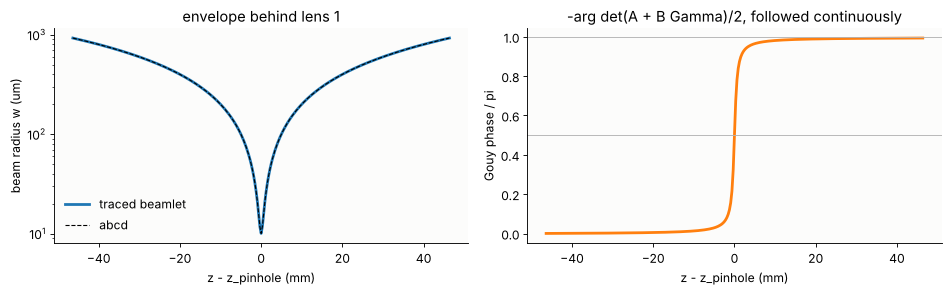

narrowest: 10.07 um at z - z_pinhole = 0.000 mm


In [3]:
zs = T1 + BFL1 + np.linspace(-(BFL1 - 1.0), BFL1 - 1.0, 301)    # includes the pinhole plane
w_z, g_z = [], []
for z in zs:
    o, _, g, _ = one.trace(lens1, z=z, details=True)
    w_z.append(np.sqrt(2/o.Gamma[0, 0, 0].imag))
    g_z.append(-g[0])
w_z, g_z = np.array(w_z), np.array(g_z)
q_lens = abcd.transform_q(abcd.compose(abcd.free_space(-Z_IN),
                                       abcd.thick_lens((N_BK7 - 1)*F1, np.inf, T1, N_BK7)),
                          abcd.q_from_waist(W_IN, 0.0, WL))
w_ref = abcd.beam_radius(q_lens + (zs - T1), WL)

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
zf = zs - T1 - BFL1
ax[0].plot(zf, 1e3*w_z, lw=2.5, color="C0", label="traced beamlet")
ax[0].plot(zf, 1e3*w_ref, "--", color="k", lw=1, label="abcd")
ax[0].set_yscale("log")
ax[0].set_xlabel("z - z_pinhole (mm)")
ax[0].set_ylabel("beam radius w (um)")
ax[0].legend(frameon=False)
ax[0].set_title("envelope behind lens 1")
ax[1].plot(zf, g_z/np.pi, lw=2.5, color="C1")
ax[1].axhline(0.5, color="0.7", lw=0.8)
ax[1].axhline(1.0, color="0.7", lw=0.8)
ax[1].set_xlabel("z - z_pinhole (mm)")
ax[1].set_ylabel("Gouy phase / pi")
ax[1].set_title("-arg det(A + B Gamma)/2, followed continuously")
plt.tight_layout()
plt.show()
print("narrowest: {:.2f} um at z - z_pinhole = {:.3f} mm".format(1e3*w_z.min(), zf[np.argmin(w_z)]))

The Gouy phase climbs from 0 to π through the focus, half of it within a
Rayleigh length ($\pi w_0^2/\lambda$ = 0.5 mm) of the waist. If it were
taken from the principal square root it would jump back by π at the
focus. Two beamlets on either side of the focus, the second one wrongly
flipped, would then interfere destructively instead of constructively.

## 2. A dirty laser beam, written as beamlets

The input is a HeNe beam ($w$ = 1 mm) with two defects:

- a **phase ripple** of 0.2 rad RMS with periods between 0.5 and 2 mm,
  the kind of wavefront noise a few imperfect windows or a dusty mirror
  leave. A period $\Lambda$ diffracts light into the angle $\lambda/\Lambda$
  = 0.3 to 1.3 mrad, which lands $f_1\lambda/\Lambda$ = 16 to 63 µm from the
  axis in the pinhole plane, against a waist of 10 µm.
- a **ghost**: a weak second beam (15 % amplitude, 2.3 % power), shifted by
  0.3 mm and tilted by 2 mrad, as a reflection from an uncoated surface
  would give. It lands 100 µm beside the main spot.

The ghost overlaps the main beam with another direction. In the overlap,
every point carries two rays, so this field has no single wavefront, and
the route through phase gradient rays (`field_to_rays()`, a ray trace,
`rays_to_field()`) does not apply.

**Beamlets from a field.** `GaussianBeamlets.from_field()` puts a beamlet on
every `step`-th sample, with the local tilt and curvature of the field there,
and a radius $w_b$ = 1.5 times the beamlet spacing $\Delta$. Gaussians on a
square grid with $w_b \ge 1.5\Delta$ add up to a constant to better than
$10^{-8}$, so the beamlet sum reproduces the field. It does so up to the
structure *within* one beamlet, where the field is approximated by a linear
amplitude and a quadratic phase. That sets the trade-off:

- the beamlets must be **small** compared to the structure of the field (the
  ripple periods here), or that structure is smoothed out;
- small beamlets diverge fast ($\lambda/(\pi w_b)$), so they are **many**,
  and each covers a large area further on, which makes the sums expensive.

In [4]:
L_IN, N_IN = 6.0, 300                                   # 20 um sampling
x_in = (np.arange(N_IN) - N_IN//2)*L_IN/N_IN
X_IN, Y_IN = np.meshgrid(x_in, x_in)
rng = np.random.default_rng(3)
kf = 2*np.pi*np.fft.fftfreq(N_IN, L_IN/N_IN)
KR = np.hypot(*np.meshgrid(kf, kf))
band = (KR > 2*np.pi/2.0) & (KR < 2*np.pi/0.5)          # periods 0.5 ... 2 mm
ripple = np.real(np.fft.ifft2(np.fft.fft2(rng.standard_normal((N_IN, N_IN)))*band))
ripple *= 0.2/ripple.std()
clean = np.exp(-(X_IN**2 + Y_IN**2)/W_IN**2)
GHOST_SHIFT, GHOST_TILT = 0.3, 2e-3
ghost = 0.15*np.exp(-((X_IN - GHOST_SHIFT)**2 + Y_IN**2)/W_IN**2)*np.exp(1j*K0*GHOST_TILT*X_IN)
u_in = clean*np.exp(1j*ripple) + ghost

print("step  beamlets  w_b (um)  max |sum - field| (rel.)  on a line, time")
for step in (1, 2, 3, 4):
    t0 = time.time()
    B = GaussianBeamlets.from_field(u_in, x_in, x_in, WL, step=step, z0=Z_IN)
    err = np.abs(B.field(X_IN[N_IN//2], Y_IN[N_IN//2]) - u_in[N_IN//2]).max()
    print("{:4d}  {:8d}  {:8.0f}  {:24.3f}  {:9.2f} s".format(
        step, len(B), 1.5e3*step*L_IN/N_IN, err, time.time() - t0))
STEP = 2
beamlets = GaussianBeamlets.from_field(u_in, x_in, x_in, WL, step=STEP, z0=Z_IN)

step  beamlets  w_b (um)  max |sum - field| (rel.)  on a line, time


   1     35080        30                     0.016       4.91 s


   2      8765        60                     0.051       0.34 s
   3      3900        90                     0.095       0.10 s
   4      2196       120                     0.162       0.05 s


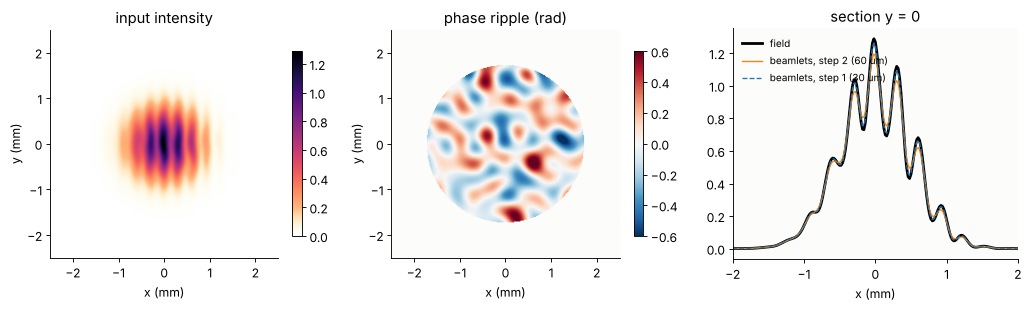

In [5]:
fig, ax = plt.subplots(1, 3, figsize=(13, 4))
ext = [x_in[0], x_in[-1], x_in[0], x_in[-1]]
im = ax[0].imshow(np.abs(u_in)**2, extent=ext, origin="lower", cmap=LIGHT)
ax[0].set_title("input intensity")
plt.colorbar(im, ax=ax[0], shrink=0.8)
im = ax[1].imshow(np.where(clean > 0.05, ripple, np.nan), extent=ext, origin="lower", cmap="RdBu_r",
                  vmin=-0.6, vmax=0.6)
ax[1].set_title("phase ripple (rad)")
plt.colorbar(im, ax=ax[1], shrink=0.8)
c = N_IN//2
B1 = GaussianBeamlets.from_field(u_in, x_in, x_in, WL, step=1, z0=Z_IN)
ax[2].plot(x_in, np.abs(u_in[c])**2, color="k", lw=2.5, label="field")
ax[2].plot(x_in, np.abs(beamlets.field(X_IN[c], Y_IN[c]))**2, color="C1", lw=1.2,
           label="beamlets, step {} ({} um)".format(STEP, int(1.5e3*STEP*L_IN/N_IN)))
ax[2].plot(x_in, np.abs(B1.field(X_IN[c], Y_IN[c]))**2, "--", color="C0", lw=1.2,
           label="beamlets, step 1 ({} um)".format(int(1.5e3*L_IN/N_IN)))
ax[2].set_xlim(-2, 2)
ax[2].set_xlabel("x (mm)")
ax[2].set_title("section y = 0")
ax[2].legend(frameon=False, fontsize=9)
for a in ax[:2]:
    a.set_xlim(-2.5, 2.5)
    a.set_ylim(-2.5, 2.5)
    a.set_xlabel("x (mm)")
    a.set_ylabel("y (mm)")
plt.tight_layout()
plt.show()

With 60 µm beamlets (step 2), about 9 000 of them, the representation is
good to 5 % of the peak. The residual sits where the ripple bends the phase
within one beamlet: it is the third order phase that a beamlet, quadratic by
construction, cannot carry. The error grows faster than linearly with the
beamlet size. Step 1 (30 µm beamlets) brings it down to under 2 %, but
with four times as many beamlets, and every later sum costs four times as
much. Step 2 is used from here on.

## 3. Through lens 1 to the pinhole plane

`trace()` carries the 9 000 beamlets through the two surfaces of lens 1, with
nine rays each, and returns them as beamlets in the pinhole plane (the image
plane of `lens1`). Their sum is the field there. For a nearly
collimated input every beamlet is focused near the pinhole, so all of them
overlap. That is the expensive part: 9 000 beamlets times 10 000 samples.

**Wave reference.** For comparison the field goes through the lens a second,
independent way, as a thin element in its principal planes. A ray traced at
height $r$ gives the optical path from the input plane to the rear principal
plane $H'$ (extended backwards along the exit ray). The input field times
$\exp(ik_0\,\mathrm{OPL}(r))$ is the field in $H'$, and `analytic_phase.propagate()`
carries it over $f_1$ to the pinhole plane with the converging sphere kept
analytic. This is exact for the lens's own wavefront (its aberrations
included) and ignores only how the lens's optical path changes with the
small angles of the ripple and the ghost.

In [6]:
t0 = time.time()
at_pinhole = beamlets.trace(lens1)
x_p = np.linspace(-0.15, 0.15, 101)                  # 3 um sampling
XP, YP = np.meshgrid(x_p, x_p)
u_p = at_pinhole.field(XP, YP)
print("{} beamlets traced and summed on {} samples in {:.1f} s".format(
    len(at_pinhole), XP.size, time.time() - t0))

# reference: thin element in the principal planes of lens 1, then angular spectrum
ZH1 = T1*(1 - 1/N_BK7)          # rear principal plane (the front one is the curved vertex)
r = np.linspace(0.0, 3.5, 400)
b = lens1.trace(Rays(np.stack([r, 0*r, np.full_like(r, Z_IN)], -1), np.tile([0.0, 0.0, 1.0], (len(r), 1)),
                     np.zeros(len(r))), last=1)
P_H, opl_H = straight_rays(b.points[-1], b.directions[-1], b.opl[-1], ZH1)
OPL = np.interp(np.hypot(X_IN, Y_IN), P_H[:, 0], opl_H)


def lens1_reference(u, x_out):
    q = QuadraticPhaseField.from_field(u*np.exp(1j*K0*OPL), x_in, x_in, WL, R=-F1)
    return propagate(q, T1 + BFL1 - ZH1, x_out=x_out, y_out=x_out).field()


u_p_ref = lens1_reference(u_in, x_p)
peak_clean = np.pi*W_IN**2/(WL*F1)                     # focus of the clean beam (input peak 1)
err = np.abs(u_p - u_p_ref).max()/np.abs(u_p_ref).max()
print("peak |u|: beamlets {:.2f}, reference {:.2f}, clean Gaussian pi w^2/(lambda f) = {:.2f}".format(
    np.abs(u_p).max(), np.abs(u_p_ref).max(), peak_clean))
print("max |difference| / peak = {:.3f}".format(err))

8765 beamlets traced and summed on 10201 samples in 13.9 s
peak |u|: beamlets 95.47, reference 96.53, clean Gaussian pi w^2/(lambda f) = 99.29
max |difference| / peak = 0.026


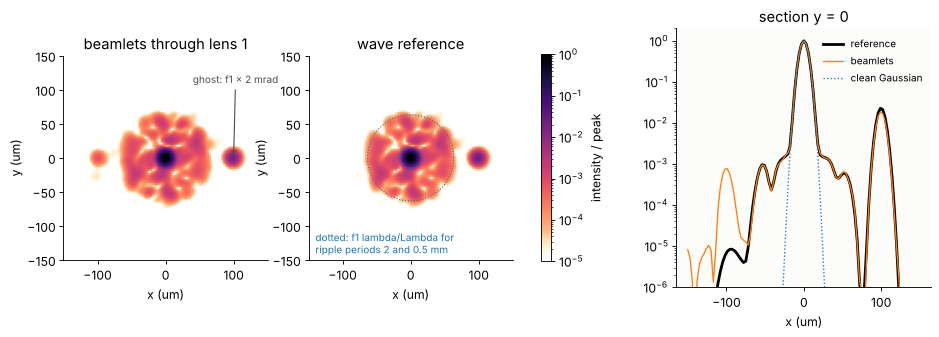

In [7]:
fig, ax = plt.subplots(1, 3, figsize=(14, 4.2))
ext = 1e3*np.array([x_p[0], x_p[-1], x_p[0], x_p[-1]])
norm = LogNorm(1e-5, 1)
I_ref = np.abs(u_p_ref)**2
for a, u, title in zip(ax[:2], (u_p, u_p_ref), ("beamlets through lens 1", "wave reference")):
    im = a.imshow(np.abs(u)**2/I_ref.max(), extent=ext, origin="lower", cmap=LIGHT, norm=norm)
    a.set_title(title)
    a.set_xlabel("x (um)")
    a.set_ylabel("y (um)")
plt.colorbar(im, ax=ax[:2], shrink=0.8, label="intensity / peak")
ax[0].annotate("ghost: f1 x 2 mrad", (1e3*F1*GHOST_TILT, 0), (40, 110), fontsize=9,
               arrowprops=dict(arrowstyle="->", color="0.3"), color="0.3")
for r_ in (1e3*F1*WL/2.0, 1e3*F1*WL/0.5):
    ax[1].add_patch(plt.Circle((0, 0), r_, fill=False, ls=":", color="C0"))
ax[1].text(-140, -140, "dotted: f1 lambda/Lambda for\nripple periods 2 and 0.5 mm", fontsize=9, color="C0")
c = len(x_p)//2
ax[2].semilogy(1e3*x_p, np.abs(u_p_ref[c])**2/I_ref.max(), color="k", lw=2.5, label="reference")
ax[2].semilogy(1e3*x_p, np.abs(u_p[c])**2/I_ref.max(), color="C1", lw=1.2, label="beamlets")
u_clean_p = lens1_reference(clean, x_p)
ax[2].semilogy(1e3*x_p, np.abs(u_clean_p[c])**2/I_ref.max(), ":", color="C0", lw=1.2,
               label="clean Gaussian")
ax[2].set_ylim(1e-6, 2)
ax[2].set_xlabel("x (um)")
ax[2].set_title("section y = 0")
ax[2].legend(frameon=False, fontsize=9)
plt.show()

The pinhole plane is the angular spectrum of the beam laid out in space
($x = f_1\theta$). The clean beam is the central spot ($w_0$ = 10 µm). The
ripple makes a speckled halo in the ring between the two dotted circles,
whose radii correspond to its shortest and longest periods. The ghost is the
separate spot 100 µm to the right, and its 0.3 mm *shift* at the input
appears here only as a phase tilt. The beamlets and the reference agree
to about 3 % of the peak and follow each other down to $10^{-4}$. Below
that, the representation error of section 2 shows, carried through the
lens (the faint spot left of the axis).

## 4. Why rays cannot pass a waist

At the pinhole the clean beam is a waist: its phase is flat. A phase
gradient ray picture (`field_to_rays()`) turns a flat phase into parallel
rays, a pencil as narrow as the waist. The real beam does something else. It leaves the waist
with the diffraction angle $\lambda/(\pi w_0)$ = 20 mrad, and lens 2
collimates it to $w = \lambda F_2/(\pi w_0) = w_\text{in} F_2/F_1$ = 3 mm. Rays carry the direction of the energy flow, and in a waist
the energy flows straight on: the divergence lives in the *width* of the
field, which a ray does not have. A beamlet has it, through
$\operatorname{Im}\Gamma$. Tracing beamlets from the same field, decomposed
at the pinhole, gives the right answer.

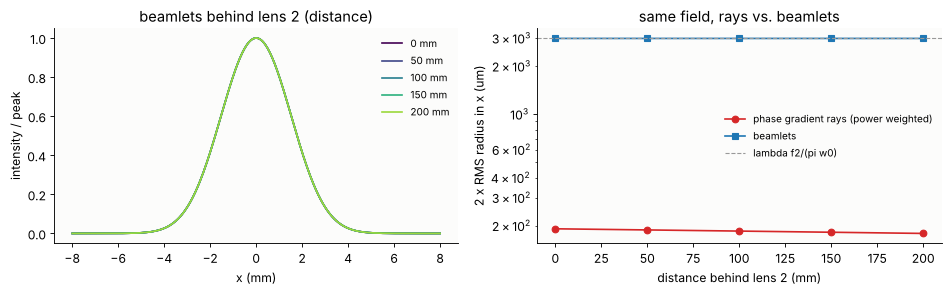

692 phase gradient rays, 1468 beamlets of radius w_b = 1.5 um


In [8]:
x_f = np.linspace(-0.05, 0.05, 201)                  # 0.5 um sampling in the pinhole plane
XF, YF = np.meshgrid(x_f, x_f)
u_f = lens1_reference(clean, x_f)                     # clean waist
sys2 = filter_lens()
# rays along the phase gradient, traced through lens 2
rays = field_to_rays(u_f, x_f, x_f, WL, step=2, threshold=1e-2)
bundle = sys2.trace(Rays(rays.points, rays.directions, rays.opl))
# beamlets from the same field
bl = GaussianBeamlets.from_field(u_f, x_f, x_f, WL, step=2, z0=0.0).trace(sys2)

zs2 = FFL2 + T2 + np.array([0.0, 50.0, 100.0, 150.0, 200.0])
x_o = np.linspace(-8, 8, 321)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
w_bl = []
for z, col in zip(zs2, plt.cm.viridis(np.linspace(0, 0.85, len(zs2)))):
    I = np.abs(bl.field(x_o, 0*x_o, z))**2
    w_bl.append(2*np.sqrt(np.sum(x_o**2*I)/np.sum(I)))
    ax[0].plot(x_o, I/I.max(), color=col, label="{:.0f} mm".format(z - FFL2 - T2))
pts, _ = straight_rays(bundle.points[-2], bundle.directions[-2], bundle.opl[-2], zs2[:, None])
ok = np.isfinite(pts[..., 0])
x_r = np.where(ok, pts[..., 0], 0.0)
ax[1].plot(zs2 - FFL2 - T2, 1e3*2*np.sqrt(np.sum(rays.power*ok*x_r**2, 1)/np.sum(rays.power*ok, 1)),
           "o-", color="C3", label="phase gradient rays (power weighted)")
ax[1].plot(zs2 - FFL2 - T2, 1e3*np.array(w_bl), "s-", color="C0", label="beamlets")
ax[1].axhline(1e3*WL*F2/(np.pi*W0), color="0.6", ls="--", lw=1, label="lambda f2/(pi w0)")
ax[1].set_yscale("log")
ax[1].set_xlabel("distance behind lens 2 (mm)")
ax[1].set_ylabel("2 x RMS radius in x (um)")
ax[1].legend(frameon=False, fontsize=9)
ax[1].set_title("same field, rays vs. beamlets")
ax[0].set_xlabel("x (mm)")
ax[0].set_ylabel("intensity / peak")
ax[0].set_title("beamlets behind lens 2 (distance)")
ax[0].legend(frameon=False, fontsize=9)
plt.tight_layout()
plt.show()
print("{} phase gradient rays, {} beamlets of radius w_b = {:.1f} um".format(
    len(rays.power), len(bl), 1.5*2*1e3*(x_f[1] - x_f[0])))

The beamlets leave lens 2 as the collimated 3 mm beam of the expander, and
it stays 3 mm wide. The phase gradient rays arrive as a pencil fifteen times
too narrow. They spread only by the slight curvature that is left in the
waist (lens 1 is not perfect), and they know nothing of the diffraction
that widens the beam.

The beamlets had to be small here. Each is 1.5 µm wide, against the
10 µm waist, because a beamlet sum smooths the field over about a beamlet
radius: with 4.5 µm beamlets the waist would come out some 10 % too wide,
and the output beam correspondingly too narrow. Small beamlets diverge
fast, by $\lambda/(\pi w_b)$ = 0.13 rad here, so each one is wider than
lens 2 by the time it gets there. `trace()` treats the lens as quadratic
around every base ray. That is fine for this weak lens, but it is the
second side of the size trade-off from section 2: a beamlet has to be
narrow compared to the field, and also narrow compared to the scale on
which the optics change.

## 5. The pinhole and lens 2

**Without a pinhole** nothing has to be redone: the 9 000 beamlets that
arrived in the pinhole plane are complete Gaussians, and they go on through
lens 2 as they are. The pinhole plane becomes the input plane of the second
system.

**With a pinhole** they cannot. The beamlets from lens 1 are 170 µm wide
in the pinhole plane, ten times the pinhole, so a beamlet cannot be cut, it
can only pass or not. The standard remedy is **re-decomposition**: sum the
beamlets in the plane of the aperture and start new, small beamlets from the
result. Here the field is evaluated on a 0.5 µm grid (±50 µm) and decomposed
into 1.5 µm beamlets. The pinhole is the first surface of the second system
(`filter_lens(a)`, a surface with `semi_diameter=a`), and `trace(clip=True)`
drops every beamlet with a ray outside it. That resolves the edge to one
beamlet radius.

The pinhole radius is $a = 1.5\,w_0$ = 15 µm. It passes $1 - e^{-2a^2/w_0^2}$
= 99 % of a clean Gaussian, and only directions below $a/f_1$ = 0.3 mrad.
That blocks the ripple (periods below 2 mm) and the ghost.

**Reference.** The pinhole is tiny compared to the 150 mm to lens 2
($a^2/\lambda f_2 \approx 0.002$), so the field at lens 2 is the far field
of the pinhole. From the angular spectrum $\tilde u(\mathbf{k}_\perp)$ of
the reference field times the pinhole it is
$u(\mathbf{x}) = -\frac{ikz}{2\pi R^2}\,\tilde u(k\mathbf{x}/R)\,e^{ikR}$ with
$R = \sqrt{z^2 + |\mathbf{x}|^2}$, evaluated in the front principal plane
of lens 2. There it is multiplied by the thin element phase of lens 2
(traced rays from the pinhole centre, from one principal plane to the
other), and `propagate()` carries it to the output plane 200 mm behind the
lens.

In [9]:
A_PIN = 1.5*W0
Z_OUT = 200.0                                        # output plane behind lens 2
t0 = time.time()
u_f_bl = at_pinhole.field(XF, YF)                    # beamlet field on the fine pinhole grid
print("pinhole field from the beamlets on {} samples: {:.1f} s".format(XF.size, time.time() - t0))
# without pinhole: the beamlets from lens 1 continue, the pinhole plane is z = 0 of filter_lens()
onward = GaussianBeamlets(at_pinhole.centres, at_pinhole.k_perp, at_pinhole.phase, at_pinhole.amplitude,
                          at_pinhole.Gamma, WL, z0=0.0)


def through_filter(u_pin, a):
    # new beamlets from the pinhole field, through the pinhole (radius a) and lens 2
    B = GaussianBeamlets.from_field(u_pin, x_f, x_f, WL, step=2, z0=0.0, threshold=1e-6)
    return B.trace(filter_lens(a, Z_OUT))


# reference: far field of the pinhole in the front principal plane H of lens 2, thin element
# phase from H to H' (traced from the pinhole centre), angular spectrum to the output plane
ZH2 = T2/N_BK7                                       # H behind the flat vertex: F2 from the pinhole
r2 = np.linspace(0, 12.0, 500)
th = np.arctan(r2/F2)
bb = filter_lens(None, 0.0).trace(Rays(np.zeros((len(r2), 3)),
                                       np.stack([np.sin(th), 0*th, np.cos(th)], -1),
                                       np.zeros(len(r2))), last=2)
P_H2, opl_H2 = straight_rays(bb.points[-1], bb.directions[-1], bb.opl[-1], FFL2 + T2)  # H' = last vertex
dphi = np.interp(r2, P_H2[:, 0], opl_H2) - np.hypot(r2, F2)
x_h = np.linspace(-10, 10, 401)
XH, YH = np.meshgrid(x_h, x_h)
x_o = np.linspace(-9, 9, 181)
XO, YO = np.meshgrid(x_o, x_o)


def filter_reference(u_pin, x, a):
    X, Y = np.meshgrid(x, x)
    u = u_pin if a is None else u_pin*(X**2 + Y**2 <= a**2)
    R = np.hypot(np.hypot(XH, YH), F2)
    ks = K0*np.linspace(-0.075, 0.075, 601)              # angular spectrum (separable DFT)
    E = np.exp(-1j*np.outer(ks, x))*(x[1] - x[0])
    S = E @ u @ E.T
    kx, ky = (K0*XH/R).ravel(), (K0*YH/R).ravel()
    from scipy.interpolate import RegularGridInterpolator
    interp = lambda part: RegularGridInterpolator((ks, ks), part)(np.column_stack([ky, kx]))
    S_h = (interp(S.real) + 1j*interp(S.imag)).reshape(XH.shape)
    u_h = -1j*K0*F2/(2*np.pi*R**2)*S_h*np.exp(1j*K0*R)
    u_h = u_h*np.exp(1j*K0*np.interp(np.hypot(XH, YH), r2, dphi))      # thin lens 2: now flat
    q = QuadraticPhaseField.from_field(u_h, x_h, x_h, WL)
    return propagate(q, Z_OUT, x_out=x_o, y_out=x_o).field()


t0 = time.time()
results = {}
for label, a in (("no pinhole", None), ("pinhole a = 1.5 w0", A_PIN)):
    B = onward.trace(filter_lens(None, Z_OUT)) if a is None else through_filter(u_f_bl, a)
    # the open reference needs the wider window, with the ghost 100 um off axis
    x_r = x_f if a else np.linspace(-0.15, 0.15, 301)
    results[label] = (B.field(XO, YO, B.z0), filter_reference(lens1_reference(u_in, x_r), x_r, a), len(B))
    u_b, u_r, nb = results[label]
    print("{:20s}: {:5d} beamlets, max |difference|/peak = {:.3f}, power ratio {:.3f}".format(
        label, nb, np.abs(u_b - u_r).max()/np.abs(u_r).max(), np.sum(np.abs(u_b)**2)/np.sum(np.abs(u_r)**2)))
print("{:.1f} s".format(time.time() - t0))

pinhole field from the beamlets on 40401 samples: 41.7 s


no pinhole          :  8765 beamlets, max |difference|/peak = 0.066, power ratio 0.990


pinhole a = 1.5 w0  :   716 beamlets, max |difference|/peak = 0.049, power ratio 0.968
40.3 s


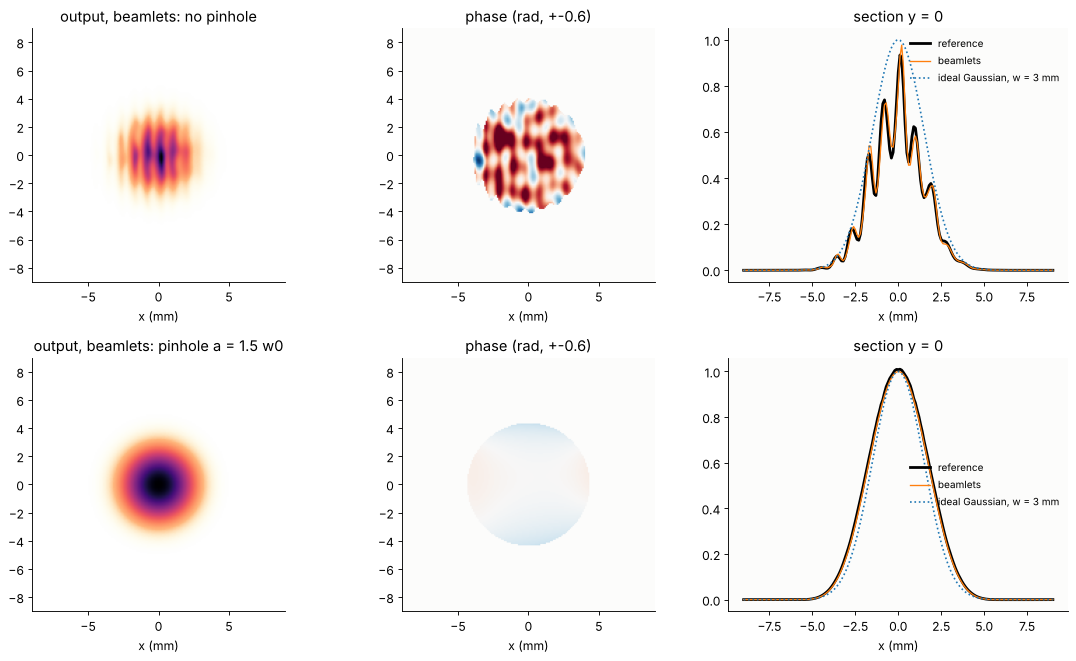

In [10]:
fig, ax = plt.subplots(2, 3, figsize=(14, 8.4))
ext = [x_o[0], x_o[-1], x_o[0], x_o[-1]]
c = len(x_o)//2
for row, (label, (u_b, u_r, nb)) in enumerate(results.items()):
    I = np.abs(u_b)**2
    im = ax[row, 0].imshow(I/I.max(), extent=ext, origin="lower", cmap=LIGHT, vmin=0, vmax=1)
    ax[row, 0].set_title("output, beamlets: " + label)
    phase = np.angle(u_b*np.conj(u_b[c, c]))
    ax[row, 1].imshow(np.where(I > 0.02*I.max(), phase, np.nan), extent=ext, origin="lower",
                      cmap="RdBu_r", vmin=-0.6, vmax=0.6)
    ax[row, 1].set_title("phase (rad, +-0.6)")
    ax[row, 2].plot(x_o, np.abs(u_r[c])**2/I.max(), color="k", lw=2.5, label="reference")
    ax[row, 2].plot(x_o, I[c]/I.max(), color="C1", lw=1.2, label="beamlets")
    ax[row, 2].plot(x_o, np.exp(-2*x_o**2/(WL*F2/(np.pi*W0))**2), ":", color="C0",
                    label="ideal Gaussian, w = 3 mm")
    ax[row, 2].set_title("section y = 0")
    ax[row, 2].legend(frameon=False, fontsize=9)
    for a in ax[row]:
        a.set_xlabel("x (mm)")
plt.tight_layout()
plt.show()

Without the pinhole the expander magnifies everything: the ripple, now
3 times longer in period, the phase noise, and the ghost. The ghost crosses
the output beam at $2/3$ mrad, because lens 2 demagnifies the angles by
$F_1/F_2$, and writes interference fringes 1 mm apart into it. With the
pinhole the output is a clean Gaussian with a flat phase. The beamlets
agree with the reference in both cases.

## 6. Choosing the pinhole

Too large a pinhole passes the noise. Too small a one cuts into the
Gaussian itself, the cut-off Gaussian then has an Airy-like far field, and
rings appear in the output beam. A sweep of the pinhole radius, each point a
new trace of the beamlets from the pinhole plane:

- **transmission**: the power through the pinhole over all the power in the
  pinhole plane (for a clean Gaussian $1 - e^{-2a^2/w_0^2}$),
- **cleanliness**: the RMS of $u_\text{out} - c\,u_\text{ideal}$ within the 1/e²
  radius, relative to the RMS of $u_\text{out}$. $u_\text{ideal}$ is the
  expander output of the clean input without pinhole, and $c$ is the best
  complex factor. Pure power loss therefore does not count, only changes of
  shape and phase.

In [11]:
u_ideal = through_filter(lens1_reference(clean, x_f), None)
u_ideal = u_ideal.field(XO, YO, u_ideal.z0)
inside = XO**2 + YO**2 <= (WL*F2/(np.pi*W0))**2
P_total = np.sum(np.abs(u_p)**2)*(x_p[1] - x_p[0])**2   # all power in the pinhole plane (+-150 um)
# share of the power in the clean beam (the ripple scatters some, the ghost adds some)
eta = np.abs(np.vdot(clean, u_in))**2/(np.vdot(clean, clean).real*np.vdot(u_in, u_in).real)


def residual(u):
    c = np.vdot(u_ideal[inside], u[inside])/np.vdot(u_ideal[inside], u_ideal[inside])
    return np.sqrt(np.mean(np.abs(u - c*u_ideal)[inside]**2)/np.mean(np.abs(u[inside])**2))


ratios = np.array([0.5, 0.75, 1.0, 1.25, 1.5, 2.0, 2.5, 3.0, 3.5, 4.0])
T, res, sections = [], [], {}
t0 = time.time()
for s in ratios:
    B = through_filter(u_f_bl, s*W0)
    u = B.field(XO, YO, B.z0)
    T.append(np.sum(np.abs(u_f_bl[XF**2 + YF**2 <= (s*W0)**2])**2)*(x_f[1] - x_f[0])**2/P_total)
    res.append(residual(u))
    if s in (0.75, 1.5, 4.0):
        sections[s] = u[len(x_o)//2]
T, res = np.array(T), np.array(res)
res_open = residual(results["no pinhole"][0])
print("{} pinholes in {:.1f} s; residual without pinhole {:.3f}; clean beam share eta = {:.3f}".format(
    len(ratios), time.time() - t0, res_open, eta))

10 pinholes in 68.6 s; residual without pinhole 0.258; clean beam share eta = 0.931


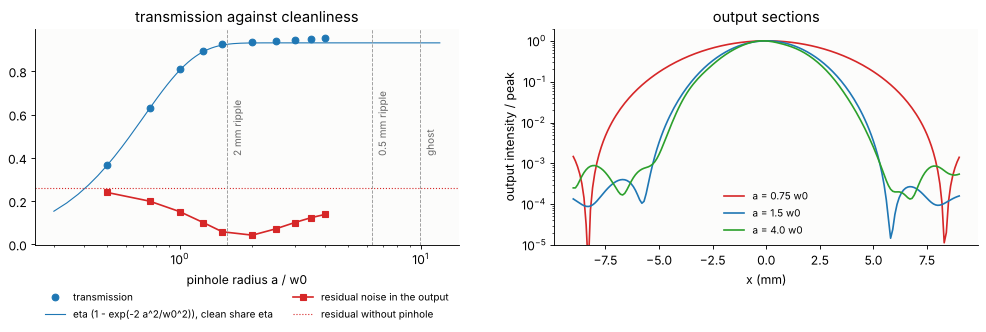

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(12.5, 4.4))
rr = np.linspace(0.3, 12, 300)
ax[0].plot(ratios, T, "o", color="C0", label="transmission")
ax[0].plot(rr, eta*(1 - np.exp(-2*rr**2)), color="C0", lw=1,
           label="eta (1 - exp(-2 a^2/w0^2)), clean share eta")
ax[0].plot(ratios, res, "s-", color="C3", label="residual noise in the output")
ax[0].axhline(res_open, color="C3", ls=":", lw=1, label="residual without pinhole")
for theta, name in ((WL/2.0, "2 mm ripple"), (WL/0.5, "0.5 mm ripple"), (GHOST_TILT, "ghost")):
    ax[0].axvline(F1*theta/W0, color="0.6", lw=0.8, ls="--")
    ax[0].text(F1*theta/W0*1.04, 0.42, name, rotation=90, fontsize=9, color="0.4")
ax[0].set_xscale("log")
ax[0].set_xlabel("pinhole radius a / w0")
ax[0].legend(frameon=False, fontsize=9, loc="upper center", bbox_to_anchor=(0.5, -0.17), ncol=2)
ax[0].set_title("transmission against cleanliness")
for (s, u), col in zip(sections.items(), ("C3", "C0", "C2")):
    ax[1].plot(x_o, np.abs(u)**2/np.abs(u).max()**2, color=col, label="a = {} w0".format(s))
ax[1].set_yscale("log")
ax[1].set_ylim(1e-5, 2)
ax[1].set_xlabel("x (mm)")
ax[1].set_ylabel("output intensity / peak")
ax[1].set_title("output sections")
ax[1].legend(frameon=False, fontsize=9)
plt.tight_layout()
plt.show()

The transmission follows $\eta\,(1 - e^{-2a^2/w_0^2})$, where $\eta$ =
0.93 is the share of the power in the clean beam (the ripple scatters 4 %
out of it, and the ghost adds 2 % elsewhere). The pinhole passes the clean
beam, and from about $1.5\,w_0$ on it passes nothing else that matters
for the power. The residual noise without a pinhole (dotted) is 26 %. The
ghost goes once $a < f_1\cdot 2$ mrad = 10 $w_0$, and the ripple goes
gradually as the pinhole closes past its angles, from the shortest periods
to the longest ($f_1\lambda/\Lambda$ = 6.3 down to 1.6 $w_0$). The residual
bottoms out at 4 to 5 % near $2\,w_0$. What remains there is the ripple
with periods close to 2 mm and the beamlet representation error. Below
about $w_0$ the residual rises again: the pinhole cuts into the Gaussian,
and the output broadens towards the Airy pattern of the pinhole (the section
for $a = 0.75\,w_0$, with its first dark ring at 8 mm).
The usual rule $a \approx 1.5$ to $2\,w_0$ (a pinhole diameter of about
$1.5\times$ the $1/e^2$ spot diameter) sits at the bottom of the valley. It
gives up about 1 % of the power and removes everything that travels more
than $a/f_1$ off the axis, which is all noise with periods shorter than
$\lambda f_1/a$ = 2 mm. Longer-period noise ends up in the spot itself,
and no pinhole can separate it from the beam.

## Summary

- `GaussianBeamlets.trace(system)` carries Gaussian beamlets through the
  real surfaces of a `raytrace.System`. Each beamlet is a base ray plus
  eight parabasal rays, the 4 × 4 ray transfer matrix of its neighbourhood
  comes from finite differences, and the complex ABCD law $\Gamma' = (C +
  D\Gamma)(A + B\Gamma)^{-1}$ gives the new width and curvature. The
  amplitude is $a/\sqrt{\det(A + B\Gamma)}$ on the branch that follows the
  beamlet through every focus (the Gouy phase), and the phase is the optical
  path of the base ray. Section 1 checks it against `abcd`: the waist, the
  Gouy phase and the Fourier plane property $A = 0$.
- Beamlets handle what rays cannot: fields with several directions at one
  point (the ghost), waists, where all the divergence lives in the width
  (section 4), and apertures inside the system, by summing the beamlets and
  decomposing the field again (section 5).
- The cost is the beamlet size. Beamlets must be small against the
  structure of the field, so there are many of them, and their sums,
  wherever the beamlets overlap, dominate the run time. Edges are resolved
  only to a beamlet radius.
- Compared to notebook [47](47_rays_and_waves.ipynb), where beamlets start
  behind the lens from a ray grid: that is cheaper when the field is a
  single wavefront in front of the lens. `trace()` is the tool when it is
  not, or when an aperture sits inside the system.
- The spatial filter is Abbe's experiment with a laser beam. The first lens
  makes the Fourier plane, the pinhole is a low-pass filter on the angular
  spectrum, and the second lens transforms back (notebook
  [52](52_abbe_image_formation.ipynb)).

## References

- J. A. Arnaud, "Representation of Gaussian beams by complex rays", Appl. Opt. 24, 538-543 (1985).
- A. W. Greynolds, "Propagation of generally astigmatic Gaussian beams along skew ray paths", Proc. SPIE 560, 33-50 (1985).
- V. Červený, M. M. Popov and I. Pšenčík, "Computation of wave fields in inhomogeneous media - Gaussian beam approach", Geophys. J. R. Astr. Soc. 70, 109-128 (1982).
- H. Kogelnik and T. Li, "Laser beams and resonators", Appl. Opt. 5, 1550-1567 (1966).
- A. E. Siegman, *Lasers*, University Science Books (1986), chapters 15 to 21 (ray matrices, Gaussian beams, the complex ABCD law).
- R. K. Luneburg, *Mathematical Theory of Optics*, University of California Press (1964).
- A. B. Porter, "On the diffraction theory of microscopic vision", Phil. Mag. 11, 154-166 (1906).
- J. W. Goodman, *Introduction to Fourier Optics*, 4th ed., W. H. Freeman (2017), chapters 5 and 8 (the Fourier transforming property of a lens, spatial filtering).

In [13]:
print("run time: {:.0f} s".format(time.time() - t_start))

run time: 185 s
